# Part 4.C — Few-shot learning and horizontal-flip augmentation

Stage C asks how many labelled positives a **frozen** representation needs, and what
horizontal flipping buys. Chosen representation: **DINOv2 ViT-S/14, 384-D CLS token**
(the Stage B baseline), L2-normalised, same `LinearSVC` as Part 1.

Protocol (identical to Stages A/B):

* positives = target category, negatives = `background`, labels `+1` / `-1`;
* the internal validation split is the one persisted by Stage A/B
  (`results/part4_internal_val_names.csv`, keyed by file name);
* `C` is selected on that internal validation set **for every shot count and seed**;
  the supplied `*_val` split is the test set and is scored once per run;
* no test image is ever flipped and no test label is used for selection.

**Negatives convention (stated once, applied to every shot count):** the training
negatives are the **full background training set, fixed**, minus the background images
that belong to the internal validation split (~815 images). Negatives are *not* matched
to the number of positives, so the only thing that changes across the curve is the number
of labelled positives.

**Shots:** 1, 5, 10, 20 and "all" available positives (the per-category count after
removing internal-validation positives). Each shot count is repeated over **3 seeds**
for mean ± standard deviation.

**Augmentation conditions (training only):**

| condition | what happens |
|---|---|
| `none` | original descriptors only |
| `flip_add` | the horizontally flipped copy of each training image is appended as an extra row (positives *and* negatives) — the frozen-backbone equivalent of data augmentation |
| `flip_avg` | each training descriptor is replaced by the average of the original and flipped embeddings |

Test-time augmentation is **not** used; the test set is never flipped.

In [1]:
import json
import os
import sys
import time
from pathlib import Path


def _find_code_dir():
    '''Locate the directory containing src/ (works from code/ or the repo root).'''
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        for candidate in (base, base / "code"):
            if (candidate / "src" / "deep_models.py").exists():
                return candidate
    raise FileNotFoundError(
        "Could not find src/deep_models.py. Open the notebook from code/ or the repo root."
    )


CODE_DIR = _find_code_dir()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import average_precision_score

from src.deep_models import getModel
from src.deep_eval import (
    BACKGROUND,
    CATEGORIES,
    DEFAULT_C_GRID,
    binary_subset,
    internal_val_names,
    l2norm,
    save_results,
    sweep_c,
    train_svm_checked,
)
from src.utils import loadSamplesTable

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# --------------------------- experiment configuration -----------------------
CATEGORY = "motorbike"                    # highlighted in the plots
CATEGORIES_TO_RUN = CATEGORIES
SHOTS = (1, 5, 10, 20, "all")
SEEDS = (0, 1, 2)
CONDITIONS = ("none", "flip_add", "flip_avg")
C_GRID = DEFAULT_C_GRID
MAX_ITER = 5000
SEED = 0
VAL_FRACTION = 0.2
TAG = "dinov2_vits14"
FLIP_TAG = "dinov2_vits14_flip"
GEM_P = 3.0
BATCH_SIZE = 32
COMPARE_RESNET = True                    # optional single-category comparison if cached

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 110
np.random.seed(SEED)

Device: cpu


## C.1 — Load the frozen DINOv2 backbone

The model is only needed for the features that are not cached yet (first run:
base train/test, plus flipped train). Loading time is reported separately.

In [2]:
t0 = time.perf_counter()
model, preprocess = getModel("dinov2_vits14", device)
model.eval()
model_load_s = time.perf_counter() - t0
print(f"DINOv2 ViT-S/14 loaded in {model_load_s:.2f}s on {device}")
print("Preprocessing:", preprocess)

Using cache found in C:\Users\HP/.cache\torch\hub\facebookresearch_dinov2_main


DINOv2 ViT-S/14 loaded in 1.12s on cpu
Preprocessing: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## C.2 — Features: cached originals + cached flipped training set

Base descriptors are the Stage B cache (`features_cls`). If the cache is absent it is
created here (all three poolings, so Stage B stays compatible). The flipped copy is
extracted for the **training split only** and cached under a separate tag.

Flipping is applied to the already-preprocessed tensor (`torch.flip` on the width axis).
Because the transform is Resize + **symmetric** CenterCrop, this is equivalent to
flipping the image before preprocessing, and it avoids reading every JPEG twice.

In [3]:
def _pool(x):
    '''One forward pass -> {'cls','mean','gem'} float tensors of shape (B, 384).'''
    feats = model.forward_features(x)
    if isinstance(feats, dict):
        cls = feats.get("x_norm_clstoken", feats.get("cls_token"))
        patches = feats.get("x_norm_patchtokens", feats.get("patch_tokens"))
    elif torch.is_tensor(feats) and feats.dim() == 3:
        cls, patches = feats[:, 0], feats[:, 1:]
    else:
        cls, patches = feats, None
    out = {"cls": cls}
    if patches is not None:
        out["mean"] = patches.mean(dim=1)
        out["gem"] = patches.relu().clamp(min=1e-6).pow(GEM_P).mean(dim=1).pow(1.0 / GEM_P)
    return {k: v.float() for k, v in out.items()}


def _extract(df, poolings=("cls",), flip=False, batch_size=BATCH_SIZE):
    acc = {k: [] for k in poolings}
    t0 = time.perf_counter()
    with torch.inference_mode():
        for start in range(0, len(df), batch_size):
            batch = df.iloc[start:start + batch_size]
            images = [preprocess(Image.open(p).convert("RGB")) for p in batch.filepath]
            x = torch.stack(images).to(device)
            if flip:
                x = torch.flip(x, dims=[3])
            descs = _pool(x)
            for k in acc:
                acc[k].append(descs[k].cpu().numpy().astype(np.float32))
    dt = time.perf_counter() - t0
    print(f"  {len(df)} images, flip={flip}, {dt:.1f}s "
          f"({1000 * dt / max(len(df), 1):.1f} ms/img)")
    return {k: np.concatenate(v, axis=0) for k, v in acc.items()}


def load_features(subset, flip=False, force=False):
    '''Return (features_cls, file_names, categories) with disk caching.'''
    tag = FLIP_TAG if flip else TAG
    cache_dir = Path("data/deep_features") / tag
    cache = cache_dir / f"{subset}.npz"
    cache_dir.mkdir(parents=True, exist_ok=True)

    if cache.exists() and not force:
        with np.load(cache, allow_pickle=True) as data:
            if "features_cls" in data.files:
                print(f"[cache] {cache} -> {data['features_cls'].shape}")
                return data["features_cls"], data["file_names"], data["categories"]

    df = loadSamplesTable("data/splits", "data/images", subset=subset, per_class=-1)
    poolings = ("cls",) if flip else ("cls", "mean", "gem")
    print(f"[extract] {subset} ({'flipped' if flip else 'original'}): {len(df)} images")
    feats = _extract(df, poolings=poolings, flip=flip)

    payload = {"file_names": df.filename.to_numpy().astype(str),
               "categories": df.category.to_numpy().astype(str)}
    for k, v in feats.items():
        payload[f"features_{k}"] = v
    np.savez_compressed(cache, **payload)
    return feats["cls"], payload["file_names"], payload["categories"]


train_features, train_names, train_categories = load_features("train")
test_features, test_names, test_categories = load_features("val")
flip_train, flip_names, flip_categories = load_features("train", flip=True)

# Align the flipped rows to the base row order by file name.
if not np.array_equal(train_names, flip_names):
    lookup = {name: i for i, name in enumerate(flip_names)}
    flip_train = flip_train[[lookup[name] for name in train_names]]

assert train_features.shape[1] == test_features.shape[1] == flip_train.shape[1] == 384
assert len(flip_train) == len(train_features)
print("Train:", train_features.shape, "| Test:", test_features.shape,
      "| Flipped train:", flip_train.shape)

[cache] data\deep_features\dinov2_vits14\train.npz -> (2791, 384)
[cache] data\deep_features\dinov2_vits14\val.npz -> (2796, 384)
[cache] data\deep_features\dinov2_vits14_flip\train.npz -> (2791, 384)
Train: (2791, 384) | Test: (2796, 384) | Flipped train: (2791, 384)


## C.3 — Shared split and per-category pools

The internal validation names are loaded from the file written by Stages A/B. If it does
not exist yet, it is recomputed with the same rule (order-independent, seed 0, 20%) and
saved, so later stages remain consistent.

In [4]:
val_path = RESULTS_DIR / "part4_internal_val_names.csv"
if val_path.exists():
    val_names = pd.read_csv(val_path, dtype={"file_name": str})["file_name"].astype(str).to_numpy()
    print(f"[cache] internal validation names: {val_path} ({len(val_names)} images)")
else:
    val_names = internal_val_names(train_names, train_categories,
                                   fraction=VAL_FRACTION, seed=SEED)
    save_results(pd.DataFrame({"file_name": val_names}), val_path)
    print(f"[computed] internal validation names ({len(val_names)} images)")

is_val = np.isin(train_names, val_names)
assert is_val.any(), (
    "No internal-validation names matched the training cache; the cached split and "
    "the feature cache come from different file-name sets."
)
assert not np.isin(test_names, val_names).any(), "internal-val and test images overlap"


def category_pools(cat):
    '''Training pools (val rows removed) and internal-validation rows for one category.'''
    pos = np.flatnonzero(train_categories == cat)
    neg = np.flatnonzero(train_categories == BACKGROUND)
    return (pos[~is_val[pos]], neg[~is_val[neg]],
            pos[is_val[pos]], neg[is_val[neg]])


pool_rows = []
for cat in CATEGORIES_TO_RUN:
    pos_tr, neg_tr, pos_va, neg_va = category_pools(cat)
    pool_rows.append(dict(category=cat, pos_train=len(pos_tr), neg_train=len(neg_tr),
                          pos_internal_val=len(pos_va), neg_internal_val=len(neg_va),
                          pos_test=int((test_categories == cat).sum())))
display(pd.DataFrame(pool_rows))

[cache] internal validation names: results\part4_internal_val_names.csv (558 images)


,category,pos_train,neg_train,pos_internal_val,neg_internal_val,pos_test
0,aeroplane,89,815,23,204,126
1,car,270,815,106,204,337
2,horse,99,815,40,204,148
3,motorbike,80,815,40,204,125
4,person,773,815,252,204,983


## C.4 — Few-shot runs

For each category, condition, shot count and seed:

1. sample `n_pos` positives **without replacement** from the training positives
   (`n_pos = "all"` uses every available positive);
2. build the training matrix according to the augmentation condition, using the fixed
   training negatives;
3. L2-normalise rows;
4. sweep `C` on the internal validation rows (positives + background) and keep the best
   validation AP;
5. refit on the training matrix and score the test split **once**.

`n_pos` is recorded as the actual number of positives (for "all" it depends on the
category), so the curves are comparable across classes.

In [5]:
test_l2 = l2norm(test_features)
test_sets = {cat: binary_subset(cat, test_l2, test_names, test_categories)
             for cat in CATEGORIES_TO_RUN}


def build_training(cat, n_pos, seed, condition):
    pos_tr, neg_tr, pos_va, neg_va = category_pools(cat)
    n_take = len(pos_tr) if n_pos == "all" else min(int(n_pos), len(pos_tr))
    if n_take == 0:
        return None
    rng = np.random.default_rng(seed)
    sel = rng.choice(pos_tr, size=n_take, replace=False)

    if condition == "none":
        X_pos, X_neg = train_features[sel], train_features[neg_tr]
    elif condition == "flip_add":
        X_pos = np.vstack([train_features[sel], flip_train[sel]])
        X_neg = np.vstack([train_features[neg_tr], flip_train[neg_tr]])
    elif condition == "flip_avg":
        X_pos = 0.5 * (train_features[sel] + flip_train[sel])
        X_neg = 0.5 * (train_features[neg_tr] + flip_train[neg_tr])
    else:
        raise ValueError(f"unknown condition {condition!r}")

    y_pos = np.ones(len(X_pos), dtype=np.int32)
    y_neg = -np.ones(len(X_neg), dtype=np.int32)
    X_tr = l2norm(np.vstack([X_pos, X_neg]))
    y_tr = np.concatenate([y_pos, y_neg])

    # internal validation rows (originals only; never flipped)
    X_va = l2norm(np.vstack([train_features[pos_va], train_features[neg_va]]))
    y_va = np.concatenate([np.ones(len(pos_va), dtype=np.int32),
                           -np.ones(len(neg_va), dtype=np.int32)])
    return X_tr, y_tr, X_va, y_va, n_take


def run_one(cat, n_pos, seed, condition):
    built = build_training(cat, n_pos, seed, condition)
    if built is None:
        return None
    X_tr, y_tr, X_va, y_va, n_take = built

    X_all = np.vstack([X_tr, X_va])
    y_all = np.concatenate([y_tr, y_va])
    val_mask = np.r_[np.zeros(len(X_tr), dtype=bool), np.ones(len(X_va), dtype=bool)]

    # fixed classifier seed: only the sampled positives change across seeds
    sweep = sweep_c(X_all, y_all, val_mask, C_GRID, max_iter=MAX_ITER, seed=SEED)
    best = sweep.loc[sweep["val_ap"].idxmax()]
    W, b, fit_s, conv, n_iter = train_svm_checked(
        X_tr, y_tr, float(best["C"]), max_iter=MAX_ITER, seed=SEED)

    X_te, y_te, _ = test_sets[cat]
    test_ap = average_precision_score(y_te, X_te @ W + b)

    return dict(category=cat, condition=condition, shot=str(n_pos), n_pos=n_take,
                seed=seed, C=float(best["C"]), val_ap=float(best["val_ap"]),
                train_ap=float(average_precision_score(y_tr, X_tr @ W + b)),
                test_ap=float(test_ap), n_train=int(len(y_tr)),
                fit_s=float(fit_s), converged=bool(conv), n_iter=n_iter)


runs = []
t_start = time.perf_counter()
for cat in CATEGORIES_TO_RUN:
    for condition in CONDITIONS:
        for shot in SHOTS:
            for seed in SEEDS:
                r = run_one(cat, shot, seed, condition)
                if r is not None:
                    runs.append(r)
    print(f"{cat:<10s} done ({time.perf_counter() - t_start:.0f}s elapsed)")

runs_df = pd.DataFrame(runs)
print(f"\n{len(runs_df)} runs in {time.perf_counter() - t_start:.0f}s")
save_results(runs_df, RESULTS_DIR / "part4c_fewshot_runs.csv")
display(runs_df.head())

aeroplane  done (7s elapsed)
car        done (17s elapsed)
horse      done (22s elapsed)
motorbike  done (28s elapsed)
person     done (48s elapsed)

225 runs in 48s


,category,condition,shot,n_pos,seed,C,val_ap,train_ap,test_ap,n_train,fit_s,converged,n_iter
0,aeroplane,none,1,1,0,0.1,0.882775,1.0,0.912816,816,0.008992,True,23
1,aeroplane,none,1,1,1,0.1,0.739504,1.0,0.865314,816,0.009250,True,21
2,aeroplane,none,1,1,2,0.1,0.799263,1.0,0.900518,816,0.009559,True,27
3,aeroplane,none,5,5,0,0.1,0.985093,1.0,0.988745,820,0.010099,True,37
4,aeroplane,none,5,5,1,0.1,1.000000,1.0,0.996852,820,0.009320,True,30


## C.5 — Mean ± standard deviation over seeds

Statistics are taken across the 3 sampling seeds (the "all" row has zero sampling
variance by construction because there is only one way to use all positives).

In [6]:
summary = (runs_df
           .groupby(["category", "condition", "shot", "n_pos"], as_index=False)
           .agg(val_ap_mean=("val_ap", "mean"), val_ap_std=("val_ap", "std"),
                test_ap_mean=("test_ap", "mean"), test_ap_std=("test_ap", "std"),
                C_mean=("C", "mean"), n_seeds=("seed", "nunique")))
summary[["val_ap_std", "test_ap_std"]] = summary[["val_ap_std", "test_ap_std"]].fillna(0.0)
save_results(summary, RESULTS_DIR / "part4c_fewshot_summary.csv")

target = summary[summary.category == CATEGORY].copy()
display(target.sort_values(["condition", "n_pos"]).round(4).reset_index(drop=True))

,category,condition,shot,n_pos,val_ap_mean,val_ap_std,test_ap_mean,test_ap_std,C_mean,n_seeds
0,motorbike,flip_add,1,1,0.8992,0.0552,0.9008,0.1013,0.1,3
1,motorbike,flip_add,5,5,0.9471,0.0151,0.9757,0.0068,3.4,3
2,motorbike,flip_add,10,10,0.9721,0.0022,0.9711,0.0040,0.7,3
3,motorbike,flip_add,20,20,0.9742,0.0085,0.9801,0.0027,3.7,3
4,motorbike,flip_add,all,80,0.9842,0.0000,0.9817,0.0000,1.0,3
5,motorbike,flip_avg,1,1,0.9031,0.0457,0.9115,0.0808,0.4,3
6,motorbike,flip_avg,5,5,0.9482,0.0153,0.9766,0.0062,0.1,3
7,motorbike,flip_avg,10,10,0.9726,0.0023,0.9729,0.0040,4.0,3
8,motorbike,flip_avg,20,20,0.9738,0.0096,0.9803,0.0028,6.7,3
9,motorbike,flip_avg,all,80,0.9860,0.0000,0.9824,0.0000,1.0,3


## C.6 — Validation and test AP vs number of labelled positives

The PDF asks for **validation AP** against the number of labelled examples; the test
panel is included because that is the number reported in the comparison table.
Error bars = ± 1 standard deviation over seeds.

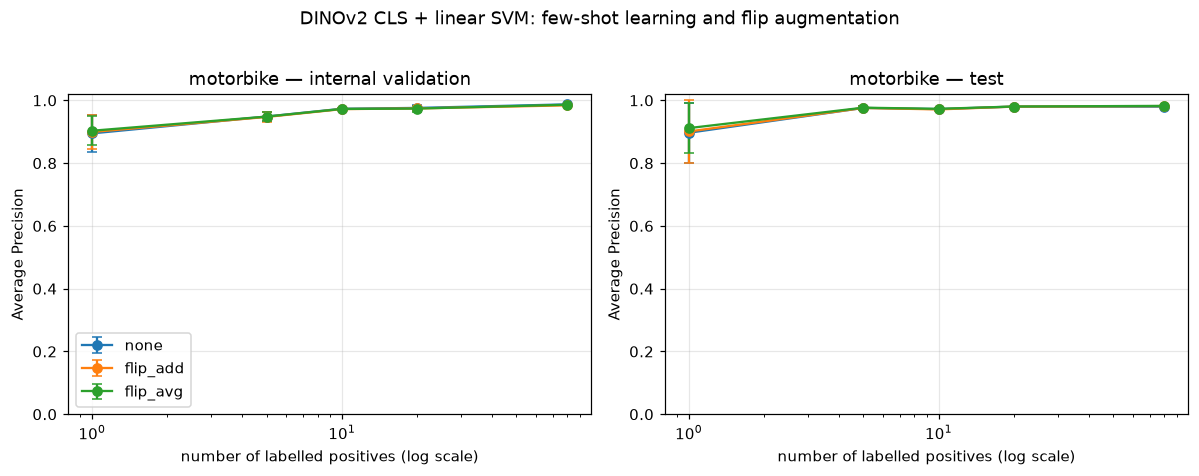

In [7]:
order = {c: i for i, c in enumerate(CONDITIONS)}
colors = {"none": "C0", "flip_add": "C1", "flip_avg": "C2"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, metric in zip(axes, ("val_ap", "test_ap")):
    for condition in CONDITIONS:
        g = target[target.condition == condition].sort_values("n_pos")
        ax.errorbar(g.n_pos, g[f"{metric}_mean"], yerr=g[f"{metric}_std"],
                    marker="o", capsize=3, color=colors[condition], label=condition)
    ax.set_xscale("log")
    ax.set_xlabel("number of labelled positives (log scale)")
    ax.set_ylabel("Average Precision")
    ax.set_title(f"{CATEGORY} — {'internal validation' if metric == 'val_ap' else 'test'}")
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1.02)
axes[0].legend()
fig.suptitle("DINOv2 CLS + linear SVM: few-shot learning and flip augmentation", y=1.02)
plt.tight_layout()
plt.show()

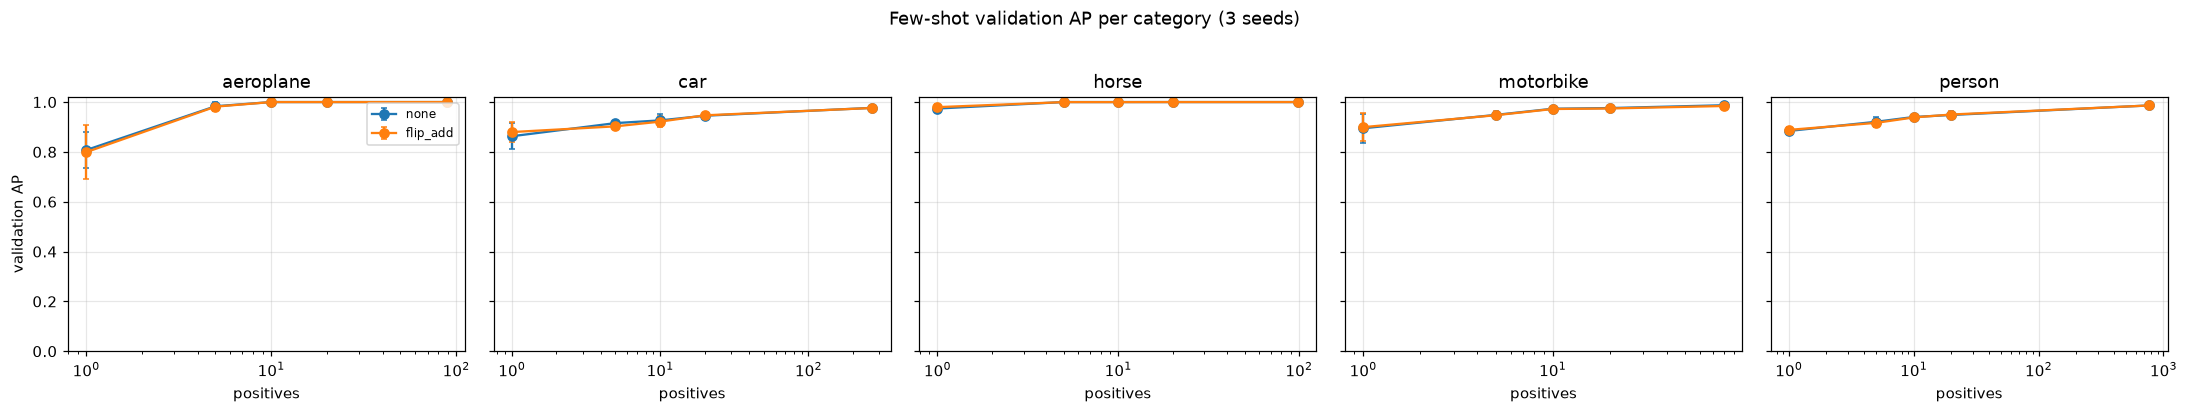

In [8]:
# Per-category view: no augmentation vs flip_add (val AP, mean ± std).
fig, axes = plt.subplots(1, len(CATEGORIES_TO_RUN), figsize=(4 * len(CATEGORIES_TO_RUN), 3.6),
                         sharey=True)
axes = np.atleast_1d(axes)
for ax, cat in zip(axes, CATEGORIES_TO_RUN):
    for condition in ("none", "flip_add"):
        g = summary[(summary.category == cat) & (summary.condition == condition)].sort_values("n_pos")
        ax.errorbar(g.n_pos, g.val_ap_mean, yerr=g.val_ap_std, marker="o", capsize=2,
                    label=condition)
    ax.set_xscale("log")
    ax.set_title(cat)
    ax.set_xlabel("positives")
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("validation AP")
axes[0].legend(fontsize=8)
fig.suptitle("Few-shot validation AP per category (3 seeds)", y=1.03)
plt.tight_layout()
plt.show()

## C.7 — Is averaging feature vectors equivalent to averaging scores?

For a **linear** classifier, averaging two descriptors and then scoring is exactly the
same as scoring both and averaging:

`W · ((f + f′) / 2) + b = ½ (W · f + b) + ½ (W · f′ + b)`

So under `flip_avg` the two procedures coincide. They stop coinciding when (a) the
averaged vector is re-normalised (L2 after averaging), or (b) the classifier is
non-linear (an MLP, RBF SVM). Averaging **scores** at test time is test-time
augmentation — a separate condition that is *not* used here. The cell verifies the
identity numerically on the fitted `flip_avg` model for the target category.

In [9]:
pos_tr, neg_tr, _, _ = category_pools(CATEGORY)
f = train_features[pos_tr]
ff = flip_train[pos_tr]

# fit the same configuration as the "all" flip_avg run, then check the identity
built = build_training(CATEGORY, "all", SEEDS[0], "flip_avg")
X_tr, y_tr, X_va, y_va, _ = built
X_all, y_all = np.vstack([X_tr, X_va]), np.concatenate([y_tr, y_va])
mask = np.r_[np.zeros(len(X_tr), dtype=bool), np.ones(len(X_va), dtype=bool)]
best = sweep_c(X_all, y_all, mask, C_GRID, max_iter=MAX_ITER, seed=SEEDS[0])
best_C = float(best.loc[best.val_ap.idxmax(), "C"])
W, b, *_ = train_svm_checked(X_tr, y_tr, best_C, max_iter=MAX_ITER, seed=SEEDS[0])

raw_avg = 0.5 * (f + ff)
s_avg_feature = raw_avg @ W + b
s_avg_scores = 0.5 * ((f @ W + b) + (ff @ W + b))
print(f"C={best_C:g}  max |score(avg feature) - avg(score)| = "
      f"{np.abs(s_avg_feature - s_avg_scores).max():.2e}")

norm_avg = l2norm(raw_avg)
s_avg_norm = norm_avg @ W + b
print(f"after L2-normalising the averaged vector, max difference = "
      f"{np.abs(s_avg_norm - s_avg_scores).max():.2e} (identity no longer holds)")

pd.DataFrame([dict(case="average features (raw)", max_abs_diff=float(np.abs(s_avg_feature - s_avg_scores).max())),
              dict(case="average features (L2 after average)", max_abs_diff=float(np.abs(s_avg_norm - s_avg_scores).max()))])

C=1  max |score(avg feature) - avg(score)| = 1.06e-06
after L2-normalising the averaged vector, max difference = 1.46e+02 (identity no longer holds)


,case,max_abs_diff
0,average features (raw),0.000001
1,average features (L2 after average),146.367077


## C.8 — Optional: DINOv2 vs ResNet-18 label efficiency (target category)

If the Stage A cache exists, the same one-vs-rest few-shot curve is computed for the
frozen ResNet-18 896-D descriptor (no augmentation). This isolates the contribution of
the pretrained representation to label efficiency.

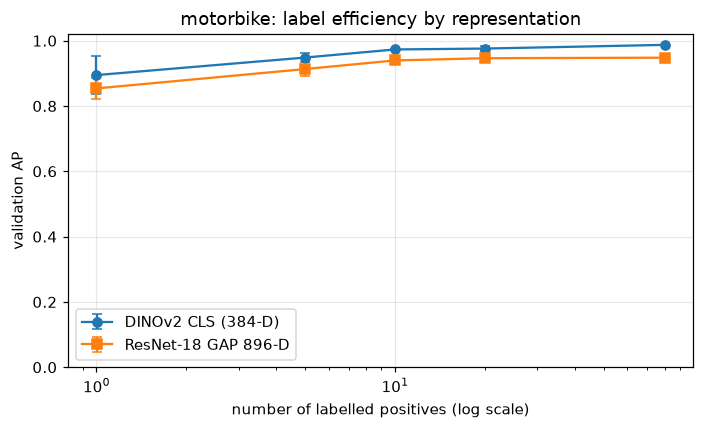

In [10]:
cmp_rows = []
res_dir = Path("data/deep_features/resnet18_gap896")
if COMPARE_RESNET:
    if (res_dir / "train.npz").exists() and (res_dir / "val.npz").exists():
        with np.load(res_dir / "train.npz", allow_pickle=True) as data:
            r_tr, r_names = data["features"], data["file_names"]
        with np.load(res_dir / "val.npz", allow_pickle=True) as data:
            r_te, r_te_names = data["features"], data["file_names"]

        # Align to the DINOv2 row order so the shared indices/labels stay valid.
        if not np.array_equal(r_names, train_names):
            lookup = {n: i for i, n in enumerate(r_names)}
            r_tr = r_tr[[lookup[n] for n in train_names]]
        if not np.array_equal(r_te_names, test_names):
            lookup = {n: i for i, n in enumerate(r_te_names)}
            r_te = r_te[[lookup[n] for n in test_names]]
        r_te = l2norm(r_te)
        Xt, yt, _ = binary_subset(CATEGORY, r_te, test_names, test_categories)

        for shot in SHOTS:
            for seed in SEEDS:
                pos_tr, neg_tr, pos_va, neg_va = category_pools(CATEGORY)
                n_take = len(pos_tr) if shot == "all" else min(int(shot), len(pos_tr))
                rng = np.random.default_rng(seed)
                sel = rng.choice(pos_tr, size=n_take, replace=False)
                X_tr = l2norm(np.vstack([r_tr[sel], r_tr[neg_tr]]))
                y_tr = np.r_[np.ones(len(sel)), -np.ones(len(neg_tr))].astype(np.int32)
                X_va = l2norm(np.vstack([r_tr[pos_va], r_tr[neg_va]]))
                y_va = np.r_[np.ones(len(pos_va)), -np.ones(len(neg_va))].astype(np.int32)
                X_all, y_all = np.vstack([X_tr, X_va]), np.r_[y_tr, y_va]
                mask = np.r_[np.zeros(len(X_tr), bool), np.ones(len(X_va), bool)]
                sw = sweep_c(X_all, y_all, mask, C_GRID, max_iter=MAX_ITER, seed=SEED)
                bc = float(sw.loc[sw.val_ap.idxmax(), "C"])
                Wr, br, *_ = train_svm_checked(X_tr, y_tr, bc, max_iter=MAX_ITER, seed=SEED)
                cmp_rows.append(dict(representation="resnet18_gap896", n_pos=n_take,
                                     seed=seed, val_ap=float(sw.val_ap.max()),
                                     test_ap=float(average_precision_score(yt, Xt @ Wr + br))))

        cmp_df = pd.DataFrame(cmp_rows)
        cmp_sum = (cmp_df.groupby(["representation", "n_pos"], as_index=False)
                   .agg(val_ap_mean=("val_ap", "mean"), val_ap_std=("val_ap", "std"),
                        test_ap_mean=("test_ap", "mean"), test_ap_std=("test_ap", "std")))
        cmp_sum[["val_ap_std", "test_ap_std"]] = cmp_sum[["val_ap_std", "test_ap_std"]].fillna(0.0)
        save_results(cmp_sum, RESULTS_DIR / "part4c_resnet_fewshot_summary.csv")

        g = target[target.condition == "none"].sort_values("n_pos")
        fig, ax = plt.subplots(figsize=(6.5, 4))
        ax.errorbar(g.n_pos, g.val_ap_mean, yerr=g.val_ap_std, marker="o", capsize=3,
                    label="DINOv2 CLS (384-D)")
        ax.errorbar(cmp_sum.n_pos, cmp_sum.val_ap_mean, yerr=cmp_sum.val_ap_std,
                    marker="s", capsize=3, label="ResNet-18 GAP 896-D")
        ax.set_xscale("log")
        ax.set_xlabel("number of labelled positives (log scale)")
        ax.set_ylabel("validation AP")
        ax.set_title(f"{CATEGORY}: label efficiency by representation")
        ax.grid(alpha=0.3)
        ax.set_ylim(0, 1.02)
        ax.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("ResNet-18 cache not found; run Stage A first.")